# Excitation K-space and Multidimensional RF Pulses

**Part:** J – advanced topics · **Reading time:** ~45 min · **Pass 1 overview:** [From signal to image](../pass1_big_picture/P1.3_From_Signal_to_Image.ipynb) · **Refreshers you may want:** [Fourier properties](../refreshers/RM4_Fourier_Properties.ipynb), [Fourier pairs & sampling](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb), [2D Fourier](../refreshers/RM6_2D_Fourier_and_Images.ipynb)

RF pulse analysis and design can be performed in the **excitation k-space** framework, which can be used for all types of pulses. It is particularly useful for multi-dimensional and spectral-spatial RF pulses.

**Why this chapter matters.** The small-tip approximation of [E1](E1_RF_Pulses.ipynb) says "profile = Fourier transform of the pulse". With time-varying gradients the same statement holds in *k-space*: the gradients move you through excitation k-space, and the RF deposits weight along the way. This one idea explains the slice-select rewinder, 2D "pencil-beam" and reduced-FOV excitations, and spectral-spatial pulses ([J2](J2_Spectral-Spatial_RF_Pulses.ipynb)).

## Learning goals

1. Describe how images are formed
    * Understand the theory of excitation k-space
    * Describe how excitation k-space is used for RF pulse design and analysis
    * Describe multidimensional and spectral-spatial RF pulses
2. *(added)* Derive the excitation k-space formula from the small-tip Bloch equation, with the sign conventions of this course.
3. *(added)* Design and Bloch-simulate a 2D spiral excitation, including its aliasing (excitation FOV).

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $\vec r$ | position | m | |
| $t$, $\tau$, $T$ | time; dummy variable; end time of the RF pulse ($t_{end}$) | s | |
| $\vec G(t)$ | gradient waveform | T/m | ≤ 40 mT/m |
| $SR$ | slew rate | T/m/s | ≤ 150–200 |
| $\gamma$, $\bar\gamma$ | gyromagnetic ratio (rad/s/T, Hz/T) | | 42.58 MHz/T |
| $\vec k_{acq}(t)$ | acquisition k-space: accumulated gradient area | 1/m | starts at 0 |
| $\vec k_{ex}(t)=\vec k(t)$ | excitation k-space: *remaining* gradient area (negative) | 1/m | ends at 0 |
| $b_1(t)$ | complex RF envelope (rotating frame) | T | µT |
| $M_{xy}(\vec r)$, $M_0$ | transverse magnetization after the pulse; equilibrium magnetization | normalized | |
| $W(\vec k)$ | RF weighting deposited in excitation k-space | T s (per k-area) | |
| $P(\vec r)$ | desired excitation profile (flip angle pattern) | rad | |
| $D(\vec k)$ | sampling density of the k-trajectory | – | |
| $k_{max}$ | extent of the trajectory | 1/m | |
| $\Delta k$ | spacing between trajectory lines / spiral turns | 1/m | |
| $FOV_{ex}=1/\Delta k$ | excitation field of view (beyond it the profile aliases) | m | |
| $n_{turns}$ | number of spiral turns | – | |
| $k_f(t)$ | spectral k-space coordinate, $-(T-t)$ | s | |
| $\Delta f$ | off-resonance | Hz | |
| $\theta$ | flip angle | rad | |

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## Excitation k-space

Excitation k-space is similar to acquisition k-space ([F2 K-space](F2_K-space.ipynb)) in many ways, so many intuitions, theoretical properties and gradient designs apply to both. Acquisition k-space describes the *measured* spatial frequencies of the object being imaged, while excitation k-space describes the *excited* spatial frequencies. They are defined as

$$\vec{k}_{acq}(t) = \bar\gamma \int_0^t \vec{G}(\tau)\, d\tau ,\qquad \vec{k}_{ex}(t) = -\bar\gamma \int_t^{T} \vec{G}(\tau)\, d\tau .$$

*In words:* acquisition k-space is the gradient area accumulated *so far*; excitation k-space is minus the gradient area *still to come* before the end of the pulse.

where $\bar\gamma=\gamma/2\pi$ [Hz/T] (the original writes $\gamma/2\pi$), $\vec G$ [T/m], $T=t_{end}$ [s] the end of the RF pulse (including any rewinder), $\tau$ the integration variable, and $\vec k$ in 1/m (cycles per metre).

As shown, they are inverted in several ways: acquisition k-space is defined by the accumulated gradient area, excitation k-space by the remaining gradient area. Acquisition k-space always *starts* at the centre of k-space, while excitation k-space always *ends* at the centre.

### Derivation (small tip, with gradients)

In the rotating frame a spin at $\vec r$ sees the off-resonance $\bar\gamma\vec G(t)\cdot\vec r$, so (see [E1](E1_RF_Pulses.ipynb)) with $M_z\approx M_0$:

$$\frac{dM_{xy}}{dt}=-i\gamma\,\vec G(t)\cdot\vec r\,M_{xy}+i\gamma b_1(t)M_0
\ \Longrightarrow\
M_{xy}(\vec r,T)\approx i\gamma M_0\int_0^T b_1(t)\,e^{-i\gamma\vec r\cdot\int_t^T\vec G(\tau)d\tau}\,dt
= i\gamma M_0\int_0^T b_1(t)\,e^{+i2\pi\vec k_{ex}(t)\cdot\vec r}\,dt .$$

*In words:* RF applied at time $t$ creates a little transverse magnetization, which is then phase-encoded by all the gradient area *remaining* until the end of the pulse – exactly the definition of $\vec k_{ex}(t)$.

where $M_{xy}(\vec r,T)$ is the transverse magnetization at the end, $b_1$ [T], $\gamma$ [rad/s/T], $M_0$ the equilibrium magnetization. (Integrating factor as in [E1](E1_RF_Pulses.ipynb); the minus sign of the precession, $e^{-i\omega t}$, and the minus sign in the definition of $\vec k_{ex}$ combine to the **plus** sign in the kernel.)

The RF profile is therefore approximately the (inverse) Fourier transform of the RF weighting deposited in excitation k-space. Writing the time integral as an integral over k-space with the trajectory's sampling density $D(\vec k)$:

$$M_{xy}(\vec r)\approx i\gamma M_0\int W(\vec k)\,e^{i2\pi\vec k\cdot\vec r}\,d\vec k,\qquad W(\vec k(t))=\frac{b_1(t)}{D(\vec k(t))} .$$

*In words:* the profile is controlled by the RF pulse shape *and* by how densely and where the gradients move through excitation k-space.

where $W$ is the k-space weighting and $D$ the density of the trajectory (k-area visited per unit time).

To use this principle, the desired profile $P(\vec r)$ (e.g. a rect) is Fourier transformed to create the desired weighting (e.g. a sinc). The RF pulse shape is this weighting, multiplied by the k-space sampling density: $b_1(t)\propto W(\vec k(t))\,D(\vec k(t))$. This last step is analogous to density compensation in non-Cartesian MRI reconstruction.

The excitation k-space trajectory defines limitations of the resulting excitation profile, analogously to acquisition k-space:
* **Resolution** – the sharpness of the excitation profile is determined by the maximum extent $k_{max}$ of the excitation k-space trajectory ($\approx1/(2k_{max})$).
* **Field of view (FOV)** – the FOV of the excitation profile is determined by the sample spacing $\Delta k$ of the trajectory, $FOV_{ex}=1/\Delta k$. Beyond this FOV, the excitation profile **aliases** (repeats).

### 1D example: the slice-select pulse in k-space

A constant gradient $G$ during the pulse plus a rewinder of area $-GT_{rf}/2$: $k_{ex}$ runs from $-\bar\gamma GT_{rf}/2$ to $+\bar\gamma GT_{rf}/2$ during the RF and returns to 0 during the rewinder. Without the rewinder the trajectory ends at the centre only *after* the RF; the RF weighting sits at $k\in[-\bar\gamma GT_{rf},0]$, i.e. off-centre → linear phase across the slice ([E2](E2_Slice_Selection.ipynb)).

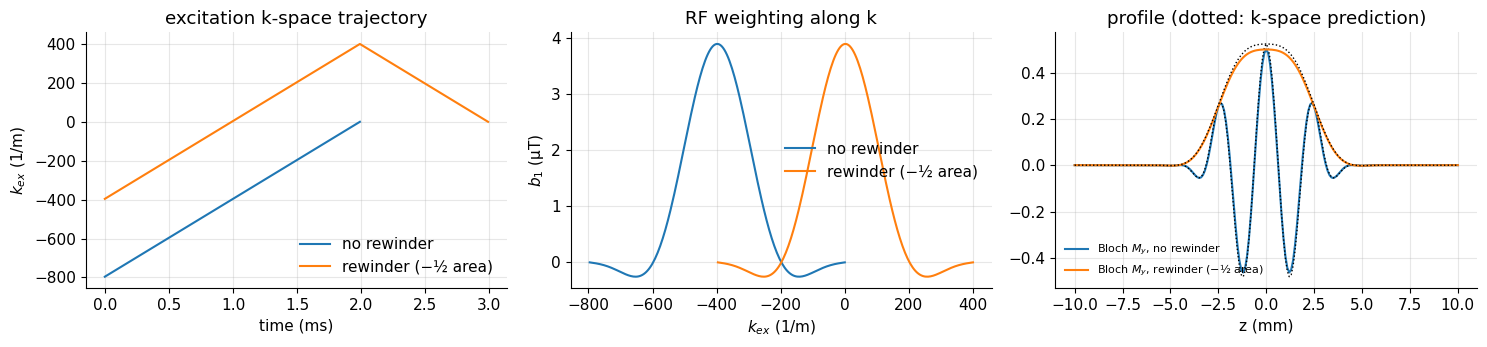

In [2]:
dt, T_rf, TBW, dz = 10e-6, 2e-3, 4, 5e-3
n = int(round(T_rf / dt)); t = (np.arange(n) + 0.5) * dt; x = (t - T_rf / 2) / T_rf
shape = np.sinc(TBW * x) * (0.54 + 0.46 * np.cos(2 * np.pi * x))
b1 = np.deg2rad(30) * shape / (mt.GAMMA * shape.sum() * dt)
G = TBW / T_rf / (mt.GAMMA_BAR * dz)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for rw, lab in [(0, "no rewinder"), (n // 2, "rewinder (−½ area)")]:
    Gw = np.concatenate([np.full(n, G), np.full(rw, -G)])
    k = -mt.GAMMA_BAR * (np.sum(Gw) - np.cumsum(Gw)) * dt         # remaining area (end of each step)
    rf = np.concatenate([b1, np.zeros(rw)]).astype(complex)
    ax[0].plot(np.arange(len(Gw)) * dt * 1e3, k, label=lab)
    ax[1].plot(k[:n], b1 * 1e6, label=lab)
    z = np.linspace(-10e-3, 10e-3, 201); r = np.zeros((z.size, 3)); r[:, 2] = z
    _, M = mt.bloch_simulate(B1=rf, dt=dt, G=np.stack([0 * Gw, 0 * Gw, Gw], 1), r=r, return_all=False)
    pred = 1j * mt.GAMMA * np.exp(2j * np.pi * np.outer(z, k)) @ rf * dt   # small-tip k-space formula
    ax[2].plot(z * 1e3, M[:, 1], label=f"Bloch $M_y$, {lab}")
    ax[2].plot(z * 1e3, pred.imag, "k:", lw=1)
ax[0].set(xlabel="time (ms)", ylabel=r"$k_{ex}$ (1/m)", title="excitation k-space trajectory"); ax[0].legend()
ax[1].set(xlabel=r"$k_{ex}$ (1/m)", ylabel=r"$b_1$ (µT)", title="RF weighting along k"); ax[1].legend()
ax[2].set(xlabel="z (mm)", title="profile (dotted: k-space prediction)"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

*Interpretation:* with the rewinder the RF weighting is centred on $k=0$ and the profile is real (all along $+y$); without it the weighting is shifted to negative $k$ and the profile is phase-modulated, so $M_y$ oscillates. The k-space formula (dotted) matches the Bloch simulation at 30°.

## Multidimensional spatially-selective pulses

To create multidimensional spatially selective pulses, first a k-space trajectory and a desired profile are chosen. Then the RF pulse shape is designed based on the desired profile (Fourier transform, small-tip approximation) and the density of the trajectory. 2D pulses are commonly designed with **spiral** or **echo-planar (EPI)** gradient waveforms. The spacing of the spiral turns or EPI lines determines the excitation FOV.

Example: a 2D Gaussian "pencil beam" of 4 cm FWHM, excited by a constant-angular-velocity spiral-in with 8 turns out to $k_{max}$ = 60 m⁻¹ in 10 ms. For a uniform-density spiral, $D\propto1/|\dot{\vec k}|$, so $b_1(t)\propto W(\vec k(t))\,|\dot{\vec k}(t)|$. Since $\vec k_{ex}=-\bar\gamma\int_t^T\vec G$, $\dot{\vec k}_{ex}=\bar\gamma\vec G$.

G_max = 7.1 mT/m, max slew = 35 T/m/s (plus an instantaneous start - see note), peak B1 = 0.75 uT, FOV_ex = n_turns/kmax = 13.3 cm


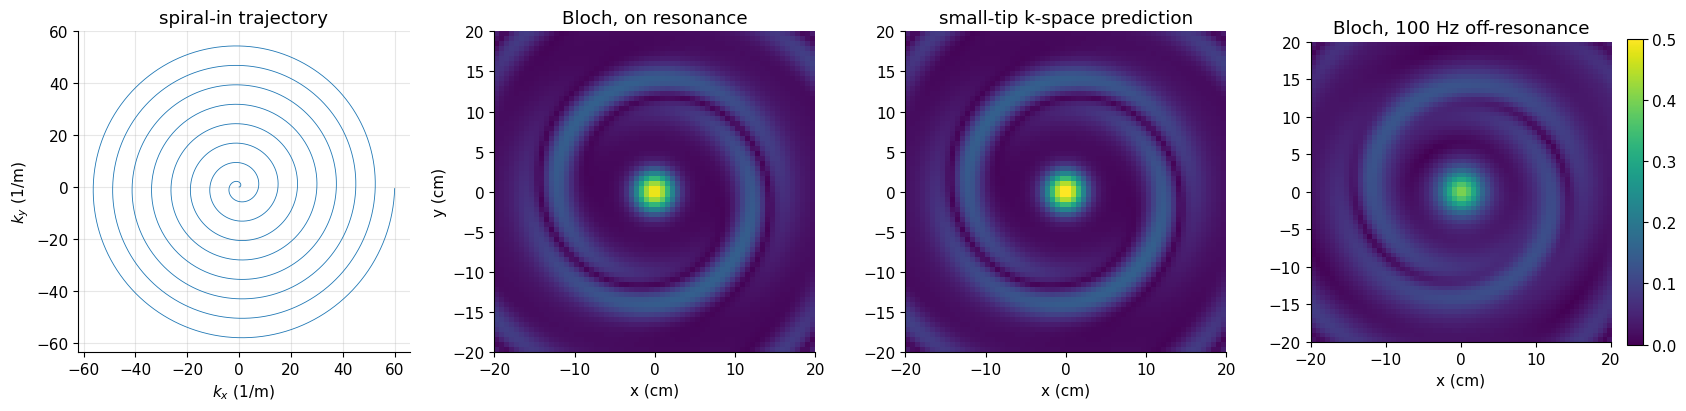

In [3]:
T, dt = 10e-3, 4e-6
Nt = int(round(T / dt)); t = (np.arange(Nt) + 0.5) * dt
n_turns, kmax = 8, 60.0                                   # turns, 1/m
u = 1 - t / T                                             # 1 -> 0  (spiral-in, ends at k = 0)
k = np.stack([kmax * u * np.cos(2 * np.pi * n_turns * u), kmax * u * np.sin(2 * np.pi * n_turns * u)], 1)
G2 = np.gradient(k, dt, axis=0) / mt.GAMMA_BAR            # dk_ex/dt = gamma_bar G   [T/m]
slew = np.abs(np.diff(G2, axis=0)).max() / dt
fwhm = 0.04; sig = fwhm / 2.355
W = np.exp(-2 * (np.pi * sig) ** 2 * np.sum(k**2, 1))      # FT of a Gaussian of std sig
b1 = W * np.linalg.norm(G2, axis=1)                        # density compensation |k_dot|
theta = np.deg2rad(30)
b1 = (theta * b1 / (mt.GAMMA * b1.sum() * dt)).astype(complex)   # flip angle 30 deg at the centre
print(f"G_max = {np.abs(G2).max()*1e3:.1f} mT/m, max slew = {slew:.0f} T/m/s (plus an instantaneous start - see note), "
      f"peak B1 = {np.abs(b1).max()*1e6:.2f} uT, FOV_ex = n_turns/kmax = {n_turns/kmax*100:.1f} cm")

Nx = 64; xs = np.linspace(-0.2, 0.2, Nx); X, Y = np.meshgrid(xs, xs)
r = np.stack([X.ravel(), Y.ravel(), 0 * X.ravel()], 1)
Gfull = np.concatenate([G2, np.zeros((Nt, 1))], 1)
results = {}
for dfv in [0.0, 100.0]:
    _, M = mt.bloch_simulate(B1=b1, dt=dt, G=Gfull, r=r, df=dfv, return_all=False)
    results[dfv] = np.abs(M[:, 0] + 1j * M[:, 1]).reshape(Nx, Nx)
pred = np.abs(1j * mt.GAMMA * np.exp(2j * np.pi * (r[:, :2] @ k.T)) @ b1 * dt).reshape(Nx, Nx)

fig, ax = plt.subplots(1, 4, figsize=(17, 4))
ax[0].plot(k[:, 0], k[:, 1], lw=0.6); ax[0].set_aspect("equal"); ax[0].set(xlabel=r"$k_x$ (1/m)", ylabel=r"$k_y$ (1/m)", title="spiral-in trajectory")
ext = [-20, 20, -20, 20]
for a, img, ttl in [(ax[1], results[0.0], "Bloch, on resonance"), (ax[2], pred, "small-tip k-space prediction"),
                    (ax[3], results[100.0], "Bloch, 100 Hz off-resonance")]:
    im = a.imshow(img, extent=ext, origin="lower", vmin=0, vmax=0.5); a.set(title=ttl, xlabel="x (cm)"); a.grid(False)
ax[1].set_ylabel("y (cm)"); plt.colorbar(im, ax=ax[3], fraction=0.046)
plt.tight_layout(); plt.show()

*Interpretation:* the centre is excited to $|M_{xy}|\approx\sin30°=0.5$ in a 4 cm spot, matching the Fourier prediction. A ring of excitation appears at radius ≈ $FOV_{ex}$ = 13 cm: the **aliasing** of the profile caused by the discrete spiral turn spacing $\Delta k=k_{max}/n_{turns}$. With 100 Hz off-resonance (e.g. fat at 1.5 T is 224 Hz) the spot blurs, because spins accumulate extra phase during the long 10 ms pulse – the main practical limitation of 2D pulses.

> **TODO (polish):** use a slew-limited spiral design (ramped start; here the gradient jumps from 0 at $t=0$, which no real amplifier can do), add an EPI-trajectory example and a disk target with Gibbs ringing.

Some use cases of 2D pulses are fast navigator acquisitions (a "pencil beam" through the diaphragm) and reduced-FOV acquisitions. The major limitations when using these pulses are the pulse duration required to traverse 2D k-space, off-resonance distortions that result during these long pulses, and gradient fidelity (delays, eddy currents) that can distort the weighting in excitation k-space.

> **🔧 Engineering reality:** Parallel transmission (several independent transmit channels, standard at 7 T) uses the different $B_1^+$ maps of the channels to "undersample" excitation k-space, like parallel imaging in reception, and shortens 2D/3D pulses several-fold ([B5](B5_RF_System_and_Receive_Chain.ipynb)).

## Spectral k-space

The concept of **spectral k-space** can be used to determine the spectral (off-resonance) profile of RF pulses. It is particularly useful for spectral-spatial RF pulses, but applies to any pulse. Off-resonance $\Delta f$ adds the factor $e^{-i2\pi\Delta f(T-t)}$ to the small-tip integral, so with

$$k_f(t)=-(T-t)\quad\Rightarrow\quad M_{xy}(\vec r,\Delta f)\approx i\gamma M_0\int_0^T b_1(t)\,e^{i2\pi[\vec k_{ex}(t)\cdot\vec r+k_f(t)\Delta f]}\,dt .$$

*In words:* the spectral "k-space" coordinate is simply minus the time remaining until the end of the pulse; it increases linearly with time.

where $k_f$ [s] is the spectral k-space coordinate and $\Delta f$ [Hz] the off-resonance.

Spectral k-space defines the accumulation of encoding in the spectral (off-resonance) domain. This information simply accumulates over time, so the spectral k-space trajectory is linear in time. In acquisitions, the accumulation in spectral k-space is equivalent to the free-induction-decay readout used in MR spectroscopy. In excitations, spectral encoding accumulates during an RF pulse. RF pulses without a gradient are spectrally selective pulses and can be interpreted as travelling in spectral excitation k-space. Slice-selective RF pulses travel on an **angled** trajectory in spectral-spatial k-space ($k_z\propto G t$, $k_f\propto t$). This angle leads to the artifact of chemical-shift (off-resonance) slice displacement: the excited band in the $(z,\Delta f)$ plane is tilted.

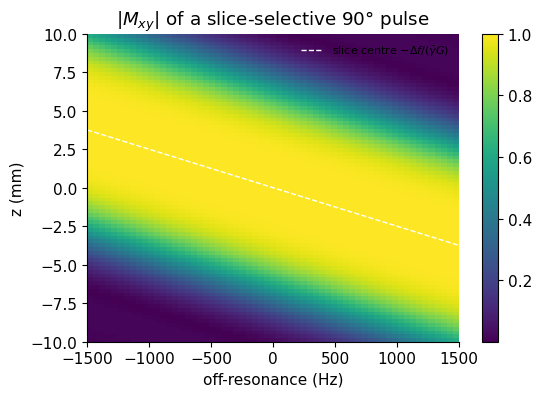

In [4]:
z = np.linspace(-10e-3, 10e-3, 81); dfs = np.linspace(-1500, 1500, 61)
Z, F = np.meshgrid(z, dfs, indexing="ij")
r = np.zeros((Z.size, 3)); r[:, 2] = Z.ravel()
b1_90 = np.pi / 2 * shape / (mt.GAMMA * shape.sum() * dt)
Gw = np.concatenate([np.full(n, G), np.full(n // 2, -G)])
_, M = mt.bloch_simulate(B1=np.concatenate([b1_90, np.zeros(n // 2)]).astype(complex), dt=dt,
                         G=np.stack([0 * Gw, 0 * Gw, Gw], 1), r=r, df=F.ravel(), return_all=False)
plt.figure(figsize=(6, 4))
plt.imshow(np.abs(M[:, 0] + 1j * M[:, 1]).reshape(Z.shape), extent=[dfs[0], dfs[-1], z[0] * 1e3, z[-1] * 1e3],
           aspect="auto", origin="lower"); plt.grid(False)
plt.plot(dfs, -dfs / (mt.GAMMA_BAR * G) * 1e3, "w--", lw=1, label=r"slice centre $-\Delta f/(\bar\gamma G)$")
plt.xlabel("off-resonance (Hz)"); plt.ylabel("z (mm)"); plt.title(r"$|M_{xy}|$ of a slice-selective 90° pulse"); plt.legend(fontsize=8)
plt.colorbar(); plt.show()

*Interpretation:* the excited band is tilted: spins 1 kHz off resonance are excited 2.5 mm away from the nominal slice. Fat at 3 T (−447 Hz) is displaced by ≈ 1.1 mm with this 2 kHz pulse.

## Spectral-spatial RF pulses

Spectral-spatial RF pulses aim to provide both
- **spectral selection**, typically to excite only protons in water molecules and not protons in lipids,
- **spatial selection**, for slice-selective imaging.

These are particularly common in fMRI and diffusion imaging with EPI, to eliminate chemical-shift displacement artifacts, and are also used for water and/or fat suppression in MR spectroscopy. They are designed by considering the spectral-spatial excitation k-space trajectory, where the deposited RF energy can be Fourier transformed to reveal the approximate spectral-spatial profile. The gradient traverses spatial excitation k-space, while time traverses the spectral dimension. The most common approach repeats a gradient and RF shape (a **sub-pulse**) many times, with modulations that create the spectral k-space weighting. The design then combines two pulses:
- a spectral pulse filter $H_f(k_f)$, applied in the $k_f$ direction to create a profile $h_f(f)$,
- a spatial pulse filter $H_z(k_z)$, applied in the $k_z$ direction to create a profile $h_z(z)$.

The resulting spectral-spatial profile is separable:

$$ h(f,z) = h_f(f)\, h_z(z) .$$

*In words:* the 2D (frequency × position) profile is the product of a spectral profile and a spatial profile.

where $h_f$ is the spectral profile (function of frequency $f$ [Hz]) and $h_z$ the spatial profile (function of $z$ [m]). The pulse is created by repeating the spatial sub-pulse, modulated by the spectral filter over the sub-pulses. The major limitations are the pulse duration required to traverse spectral-spatial k-space, small spectral FOVs limited by the sub-pulse switching rate, and gradient fidelity. Full design and simulation: [J2 Spectral-Spatial RF Pulses](J2_Spectral-Spatial_RF_Pulses.ipynb).

## Key takeaways

* Excitation k-space: $\vec k_{ex}(t)=-\bar\gamma\int_t^T\vec G\,d\tau$ – the remaining gradient area; it always ends at $k=0$.
* Small tip: $M_{xy}(\vec r)\approx i\gamma M_0\int b_1(t)e^{+i2\pi\vec k_{ex}(t)\cdot\vec r}dt$ – the profile is the Fourier transform of the RF weighting along the trajectory.
* Design: FT the desired profile, sample it along a trajectory, multiply by the trajectory density ($|\dot{\vec k}|$ for uniform spirals).
* $k_{max}$ sets the profile sharpness, the line/turn spacing sets $FOV_{ex}$ (aliasing beyond it).
* Time is spectral k-space ($k_f=-(T-t)$); a slice-selective pulse is a tilted line in $(k_z,k_f)$, causing chemical-shift slice displacement.
* 2D pulses are long → off-resonance blurring and gradient-fidelity problems; parallel transmit helps.

## Check your understanding

1. Where in excitation k-space is the trajectory at the end of every pulse, and why?

<details><summary>Answer</summary>

At $k=0$: by definition no gradient area remains after the end, $\int_T^T\vec G=0$.

</details>

2. A spiral excitation has 10 turns out to $k_{max}$ = 50 m⁻¹. What is the excitation FOV?

<details><summary>Answer</summary>

$\Delta k=k_{max}/n_{turns}=5$ m⁻¹, $FOV_{ex}=1/\Delta k=20$ cm.

</details>

3. Why is the kernel $e^{+i2\pi\vec k\cdot\vec r}$ in excitation but $e^{-i2\pi\vec k\cdot\vec r}$ in acquisition?

<details><summary>Answer</summary>

Both come from the same precession $e^{-i\gamma\vec G\cdot\vec r\,t}$; in acquisition the phase is the area accumulated so far ($+\vec k_{acq}$), in excitation the area still to come, which we define as $\vec k_{ex}=-\bar\gamma\int_t^T\vec G$, flipping the sign of the exponent.

</details>

4. A slice-select pulse has $BW_{rf}$ = 1 kHz. How far is fat at 1.5 T displaced, in units of the slice thickness?

<details><summary>Answer</summary>

$|\Delta f_{cs}|/BW_{rf}=224/1000\approx0.22$ slice thicknesses.

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "Excitation K-space".
Changes: added the derivation of the excitation k-space formula with explicit sign conventions, a 1D k-space view of the rewinder, a Bloch-simulated 2D spiral excitation with aliasing and off-resonance, and a spectral-spatial (z, Δf) profile showing chemical-shift displacement.*